In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [11]:
corpus = ["apple banana fruit", "banana apple fruit", "banana fruit apple",
                 "dog cat animal", "cat animal dog", "cat dog animal","grape apple apple","fish dog dog"]

In [12]:
corpus = [sent.split(" ") for sent in corpus]
corpus

[['apple', 'banana', 'fruit'],
 ['banana', 'apple', 'fruit'],
 ['banana', 'fruit', 'apple'],
 ['dog', 'cat', 'animal'],
 ['cat', 'animal', 'dog'],
 ['cat', 'dog', 'animal'],
 ['grape', 'apple', 'apple'],
 ['fish', 'dog', 'dog']]

In [13]:
flatten = lambda l: [item for sublist in l for item in sublist]
vocab = list(set(flatten(corpus)))
vocab

['apple', 'cat', 'animal', 'fish', 'fruit', 'grape', 'banana', 'dog']

In [14]:
word2indx = {v : indx for indx , v in enumerate(vocab)}
word2indx

{'apple': 0,
 'cat': 1,
 'animal': 2,
 'fish': 3,
 'fruit': 4,
 'grape': 5,
 'banana': 6,
 'dog': 7}

In [15]:
indx2word = {indx : v for indx , v in enumerate(vocab)}
indx2word

{0: 'apple',
 1: 'cat',
 2: 'animal',
 3: 'fish',
 4: 'fruit',
 5: 'grape',
 6: 'banana',
 7: 'dog'}

In [16]:
vocab.append("<UNK>")
word2indx["<UNK>"] = 6
indx2word[6] = "<UNK>"

In [17]:
def Random_batch(batch_size,corpus):
    skipgram = []
    for doc in corpus:
        for i in range(1,len(doc)-1):
            center = word2indx[doc[i]]
            outside = (word2indx[doc[i-1]],word2indx[doc[i+1]])
            for each_outside in outside:
                skipgram.append([center,each_outside])
    random_index = np.random.choice(range(len(skipgram)),batch_size,replace = False)
    inputs,label = [],[]
    for indx in random_index:
        inputs.append([skipgram[indx][0]])
        label.append([skipgram[indx][1]])
    return np.array(inputs),np.array(label)

In [22]:
z = 0.001
from collections import Counter

word_count = Counter(flatten(corpus))
num_total_word = sum([c for w,c in word_count.items()])
num_total_word

24

In [29]:
unigram_table = []

for v in vocab:
    uw = word_count[v] / num_total_word
    uw = int((uw ** 0.75) / z)
    unigram_table.extend([v] * uw)

Counter(unigram_table)

Counter({'apple': 308,
         'dog': 308,
         'cat': 210,
         'animal': 210,
         'fruit': 210,
         'banana': 210,
         'fish': 92,
         'grape': 92})

In [30]:
def prepare_seq(seq,word2indx):
    indx = list(map(lambda w : word2indx[w] if word2indx.get(w) is not None else word2indx["<UNK>"],seq))
    return torch.LongTensor(indx)

In [32]:
import random
def negitive_sampling(targets,unigram_table,k):
    batch_size = targets.shape[0]
    neg_sample = []
    for i in range(batch_size):
        target_indx = targets[0].item()
        n_sample = []
        while (len(n_sample) < k):
            neg = random.choice(unigram_table)
            if word2indx[neg] == target_indx:
                continue
            n_sample.append(neg)
        neg_sample.append(prepare_seq(n_sample,word2indx).reshape(1,-1)) 
    return torch.cat(neg_sample)

In [34]:
batch_size = 2
x ,y = Random_batch(batch_size,corpus)
x_tensor = torch.LongTensor(x)
y_tensor = torch.LongTensor(y)
k = 5
neg_sample = negitive_sampling(y_tensor,unigram_table,k)
neg_sample

tensor([[7, 1, 7, 3, 6],
        [2, 0, 2, 3, 0]])

In [41]:
class skipgramNeg(nn.Module):

    def __init__(self,vocab_size,emb_size):
        super(skipgramNeg,self).__init__()
        self.embedding_center = nn.Embedding(vocab_size,emb_size)
        self.embedding_outside = nn.Embedding(vocab_size,emb_size)
        self.logsigmoid = nn.LogSigmoid()


    def forward(self,center,outside,negitve_words):
        center_embedding = self.embedding_center(center)
        outside_embedding = self.embedding_outside(outside)
        neg_embedding = self.embedding_outside(negitve_words)


        uocv = outside_embedding.bmm(center_embedding.transpose(1,2)).squeeze(2)
        ukvc = - neg_embedding.bmm(center_embedding.transpose(1,2)).squeeze(2)
        ukvc_sum = torch.sum(ukvc,1).reshape(-1,1)
        loss = self.logsigmoid(uocv) + self.logsigmoid(ukvc_sum)
        return - torch.mean(loss)

In [42]:
emb_size = 2
vocab_size = len(vocab)
model = skipgramNeg(vocab_size,emb_size)


In [43]:
loss = model(x_tensor,y_tensor,neg_sample)

In [44]:
loss

tensor(0.9840, grad_fn=<NegBackward0>)

In [47]:
optimizer = optim.Adam(model.parameters(),lr = 0.001)

In [49]:
num_epoch = 5000
for epoch in range(num_epoch):
    input_batch , label_batch = Random_batch(batch_size,corpus)
    input_tensor = torch.LongTensor(input_batch) 
    label_tensor = torch.LongTensor(label_batch)

    loss = model(input_tensor,label_tensor,neg_sample)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if(epoch+1) % 1000 ==0:
        print(f"Epoch {epoch+1} | Loss {loss:2.6f}")



Epoch 1000 | Loss 0.074330
Epoch 2000 | Loss 0.518677
Epoch 3000 | Loss 1.446675
Epoch 4000 | Loss 0.061171
Epoch 5000 | Loss 0.632201


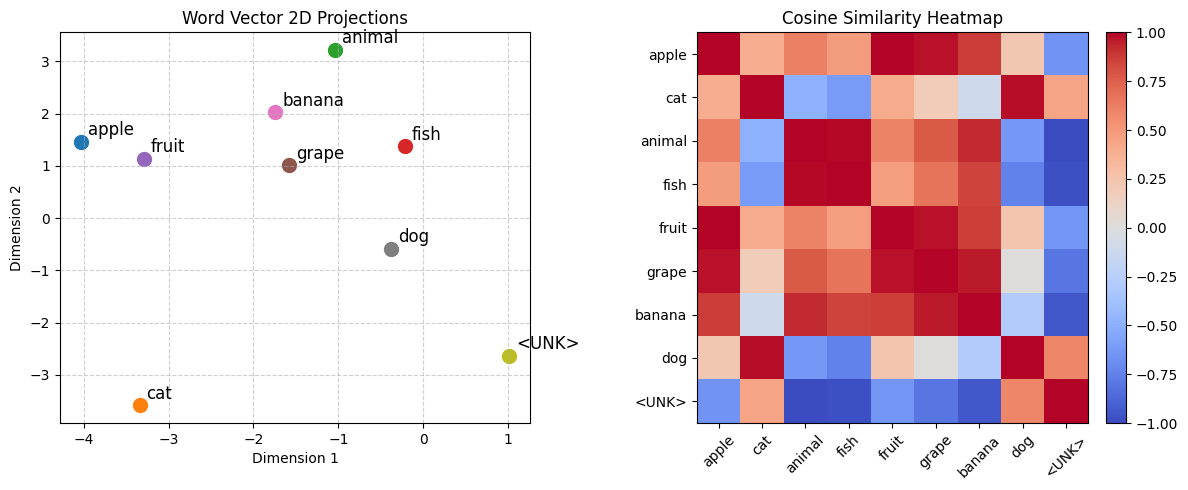

In [50]:
# Extract the trained word vectors from the model's center embeddings
trained_embeddings = model.embedding_center.weight.data.numpy()

# 1. Plot the 2D Scatter Plot of Embeddings
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for i, w in enumerate(vocab):
    x_val, y_val = trained_embeddings[i, 0], trained_embeddings[i, 1]
    plt.scatter(x_val, y_val, s=100)
    plt.annotate(w, xy=(x_val, y_val), xytext=(5, 2), textcoords='offset points', ha='left', va='bottom', fontsize=12)
plt.title("Word Vector 2D Projections")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Compute and Plot Pairwise Cosine Similarity
# Add small epsilon to avoid division by zero
norms = np.linalg.norm(trained_embeddings, axis=1, keepdims=True)
norms = np.where(norms == 0, 1e-9, norms)
norm_embeddings = trained_embeddings / norms
cosine_sim_matrix = np.dot(norm_embeddings, norm_embeddings.T)

plt.subplot(1, 2, 2)
im = plt.imshow(cosine_sim_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(vocab)), vocab, rotation=45, fontsize=10)
plt.yticks(range(len(vocab)), vocab, fontsize=10)
plt.title("Cosine Similarity Heatmap")
plt.tight_layout()
plt.show()
